# 05 — Ensemble Learning

**Obrigatório:** Random Forest. **Segundo método:** Gradient Boosting.

**Objetivo:** treinar os dois ensembles, ajustar hiperparâmetros, gerar a **curva de erro em função do número de árvores**, medir **importância das variáveis** e discutir **viés × variância**. Mesma divisão e mesmas métricas dos demais modelos.

In [1]:
import sys, json, os
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from sklearn.metrics import log_loss

from src.config import (
    SEED, CLASSIFICATION_TARGET, REGRESSION_TARGET, RISK_CLASSES,
    REPORTS_DIR, TABLES_DIR, FIGURES_DIR,
)
from src.data import split_train_test, encode_target
from src import metrics

np.random.seed(SEED)
sns.set_theme(style='whitegrid')
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
MODELOS_DIR = REPORTS_DIR / 'models'
MODELOS_DIR.mkdir(parents=True, exist_ok=True)
(REPORTS_DIR / 'predictions').mkdir(parents=True, exist_ok=True)
print('Semente:', SEED)

Semente: 42


## 1) Dados e divisão

Os ensembles também são invariantes à escala das variáveis (cada split é univariado), então não há padronização — o que preserva a interpretabilidade das importâncias.

In [2]:
df_reg = pd.read_csv('../data/processed/dataset_regression.csv')
df_clf = pd.read_csv('../data/processed/dataset_classification.csv')

Xr_train, Xr_test, yr_train, yr_test = split_train_test(df_reg, REGRESSION_TARGET, stratify=False)
Xc_train, Xc_test, yc_train_raw, yc_test_raw = split_train_test(df_clf, CLASSIFICATION_TARGET, stratify=True)
yc_train = encode_target(yc_train_raw)
yc_test = encode_target(yc_test_raw)

print('Treino:', Xc_train.shape, '| Teste:', Xc_test.shape)

Treino: (40000, 85) | Teste: (10000, 85)


## 2) Random Forest — configuração e ajuste

Ajuste com `RandomizedSearchCV` (CV=3, 6 candidatos) para conter o custo. `n_estimators` é mantido em **100**, que é a configuração final reportada.

In [3]:
espaco_rf = {
    'n_estimators': [100],
    'max_depth': [10, 20, None],
    'min_samples_leaf': [1, 5, 10],
    'max_features': ['sqrt', 0.5],
}

busca_rf_c = RandomizedSearchCV(
    RandomForestClassifier(random_state=SEED, n_jobs=-1),
    espaco_rf, n_iter=6, cv=3, scoring='f1_macro',
    random_state=SEED, n_jobs=1, refit=True,
)
busca_rf_c.fit(Xc_train, yc_train)

busca_rf_r = RandomizedSearchCV(
    RandomForestRegressor(random_state=SEED, n_jobs=-1),
    {**espaco_rf, 'max_features': ['sqrt', 0.5, 1.0]},
    n_iter=6, cv=3, scoring='neg_root_mean_squared_error',
    random_state=SEED, n_jobs=1, refit=True,
)
busca_rf_r.fit(Xr_train, yr_train)

print('RF Classificação — melhor:', busca_rf_c.best_params_)
print('F1-macro CV: {:.4f} ± {:.4f}'.format(
    busca_rf_c.best_score_, busca_rf_c.cv_results_['std_test_score'][busca_rf_c.best_index_]))
print('\nRF Regressão — melhor:', busca_rf_r.best_params_)
print('RMSE CV: {:.4f} ± {:.4f}'.format(
    -busca_rf_r.best_score_, busca_rf_r.cv_results_['std_test_score'][busca_rf_r.best_index_]))

RF Classificação — melhor: {'n_estimators': 100, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 10}
F1-macro CV: 0.7958 ± 0.0026

RF Regressão — melhor: {'n_estimators': 100, 'min_samples_leaf': 10, 'max_features': 1.0, 'max_depth': 10}
RMSE CV: 8.8544 ± 0.0190


## 3) Gradient Boosting — configuração

O custo de um `GridSearchCV` completo em 40 mil linhas é alto. Faz-se uma **busca manual em subamostra de 25% do treino** (3 configurações, com validação interna), e a melhor configuração é refeita no treino completo com **100 estimadores**. Isso está documentado como decisão de orçamento computacional.

In [4]:
Xc_sub, Xc_val, yc_sub, yc_val = train_test_split(
    Xc_train, yc_train, test_size=0.25, random_state=SEED, stratify=yc_train)
Xr_sub, Xr_val, yr_sub, yr_val = train_test_split(
    Xr_train, yr_train, test_size=0.25, random_state=SEED)

candidatos_gb = [
    {'max_depth': 3, 'learning_rate': 0.10},
    {'max_depth': 2, 'learning_rate': 0.10},
    {'max_depth': 3, 'learning_rate': 0.05},
]

linhas_gb = []
for params in candidatos_gb:
    modelo = GradientBoostingClassifier(n_estimators=60, random_state=SEED, **params)
    modelo.fit(Xc_sub, yc_sub)
    f1 = metrics.classification_metrics(yc_val, modelo.predict(Xc_val))['F1 (macro)']
    linhas_gb.append({**params, 'F1_validacao': f1})

    modelo_r = GradientBoostingRegressor(n_estimators=60, random_state=SEED, **params)
    modelo_r.fit(Xr_sub, yr_sub)
    rmse = metrics.regression_metrics(yr_val, modelo_r.predict(Xr_val))['RMSE']
    linhas_gb[-1]['RMSE_validacao'] = rmse

busca_gb = pd.DataFrame(linhas_gb).sort_values('F1_validacao', ascending=False)
busca_gb.to_csv(TABLES_DIR / '05_busca_gradient_boosting.csv', index=False)

melhor_gb = busca_gb.iloc[0][['max_depth', 'learning_rate']].to_dict()
melhor_gb = {k: (int(v) if k == 'max_depth' else float(v)) for k, v in melhor_gb.items()}
print('Melhor configuração (subamostra):', melhor_gb)
busca_gb.round(4)

Melhor configuração (subamostra): {'max_depth': 2, 'learning_rate': 0.1}


,max_depth,learning_rate,F1_validacao,RMSE_validacao
1,2,0.10,0.8023,8.9499
2,3,0.05,0.7992,9.0155
0,3,0.10,0.7991,8.8935


## 4) Treinamento final dos ensembles (n = 100 árvores)

Mede-se tempo e pico de memória do treinamento. As métricas de treino e teste permitem calcular o *gap* exato.

In [5]:
from src.profiling import profile_training

def treinar_final(nome, fabrica):
    resultado = profile_training(fabrica)
    return resultado['modelo'], resultado

def construir_rf_c():
    modelo = RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1, **{
        k: v for k, v in busca_rf_c.best_params_.items() if k != 'n_estimators'})
    modelo.fit(Xc_train, yc_train)
    return modelo

def construir_rf_r():
    modelo = RandomForestRegressor(n_estimators=100, random_state=SEED, n_jobs=-1, **{
        k: v for k, v in busca_rf_r.best_params_.items() if k != 'n_estimators'})
    modelo.fit(Xr_train, yr_train)
    return modelo

rf_c, treino_rf_c = treinar_final('RF Classificação', construir_rf_c)
rf_r, treino_rf_r = treinar_final('RF Regressão', construir_rf_r)

gb_params = {'n_estimators': 100, **melhor_gb}

def construir_gb_c():
    modelo = GradientBoostingClassifier(random_state=SEED, **gb_params)
    modelo.fit(Xc_train, yc_train)
    return modelo

def construir_gb_r():
    modelo = GradientBoostingRegressor(random_state=SEED, **gb_params)
    modelo.fit(Xr_train, yr_train)
    return modelo

gb_c, treino_gb_c = treinar_final('GB Classificação', construir_gb_c)
gb_r, treino_gb_r = treinar_final('GB Regressão', construir_gb_r)

tempos_treino = pd.DataFrame([
    {'Modelo': 'RandomForest (n=100)', 'Problema': 'Classificacao',
     'Tempo_treino_s': treino_rf_c['tempo_treinamento_s'],
     'Pico_memoria_treino_kb': treino_rf_c['pico_memoria_treinamento_kb']},
    {'Modelo': 'RandomForest (n=100)', 'Problema': 'Regressao',
     'Tempo_treino_s': treino_rf_r['tempo_treinamento_s'],
     'Pico_memoria_treino_kb': treino_rf_r['pico_memoria_treinamento_kb']},
    {'Modelo': 'GradientBoosting (n=100)', 'Problema': 'Classificacao',
     'Tempo_treino_s': treino_gb_c['tempo_treinamento_s'],
     'Pico_memoria_treino_kb': treino_gb_c['pico_memoria_treinamento_kb']},
    {'Modelo': 'GradientBoosting (n=100)', 'Problema': 'Regressao',
     'Tempo_treino_s': treino_gb_r['tempo_treinamento_s'],
     'Pico_memoria_treino_kb': treino_gb_r['pico_memoria_treinamento_kb']},
])
tempos_treino.to_csv(TABLES_DIR / '05_tempos_treino.csv', index=False)
tempos_treino.round(4)

,Modelo,Problema,Tempo_treino_s,Pico_memoria_treino_kb
0,RandomForest (n=100),Classificacao,9.2034,39850.8779
1,RandomForest (n=100),Regressao,17.7870,39849.1973
2,GradientBoosting (n=100),Classificacao,60.8673,39847.3818
3,GradientBoosting (n=100),Regressao,20.6085,39847.4639


In [6]:
def avaliar_clf(modelo, nome):
    pred_tr, pred_te = modelo.predict(Xc_train), modelo.predict(Xc_test)
    proba_tr, proba_te = modelo.predict_proba(Xc_train), modelo.predict_proba(Xc_test)
    m_tr = metrics.classification_metrics(yc_train, pred_tr, proba_tr, classes=[0, 1, 2])
    m_te = metrics.classification_metrics(yc_test, pred_te, proba_te, classes=[0, 1, 2])
    return m_tr, m_te, pred_tr, pred_te, proba_tr, proba_te

def avaliar_reg(modelo, nome):
    pred_tr, pred_te = modelo.predict(Xr_train), modelo.predict(Xr_test)
    m_tr = metrics.regression_metrics(yr_train, pred_tr)
    m_te = metrics.regression_metrics(yr_test, pred_te)
    return m_tr, m_te, pred_tr, pred_te

m_rf_c_tr, m_rf_c_te, pred_rf_c_tr, pred_rf_c_te, proba_rf_c_tr, proba_rf_c_te = avaliar_clf(rf_c, 'RandomForest')
m_gb_c_tr, m_gb_c_te, pred_gb_c_tr, pred_gb_c_te, proba_gb_c_tr, proba_gb_c_te = avaliar_clf(gb_c, 'GradientBoosting')
m_rf_r_tr, m_rf_r_te, pred_rf_r_tr, pred_rf_r_te = avaliar_reg(rf_r, 'RandomForest')
m_gb_r_tr, m_gb_r_te, pred_gb_r_tr, pred_gb_r_te = avaliar_reg(gb_r, 'GradientBoosting')

resumo = pd.DataFrame([
    {'Modelo': 'RandomForest', 'Problema': 'Classificacao', 'Conjunto': 'Treino', 'F1_macro': m_rf_c_tr['F1 (macro)'], 'Gap': None},
    {'Modelo': 'RandomForest', 'Problema': 'Classificacao', 'Conjunto': 'Teste', 'F1_macro': m_rf_c_te['F1 (macro)'],
     'Gap': m_rf_c_tr['F1 (macro)'] - m_rf_c_te['F1 (macro)']},
    {'Modelo': 'GradientBoosting', 'Problema': 'Classificacao', 'Conjunto': 'Treino', 'F1_macro': m_gb_c_tr['F1 (macro)'], 'Gap': None},
    {'Modelo': 'GradientBoosting', 'Problema': 'Classificacao', 'Conjunto': 'Teste', 'F1_macro': m_gb_c_te['F1 (macro)'],
     'Gap': m_gb_c_tr['F1 (macro)'] - m_gb_c_te['F1 (macro)']},
    {'Modelo': 'RandomForest', 'Problema': 'Regressao', 'Conjunto': 'Treino', 'RMSE': m_rf_r_tr['RMSE'], 'Gap': None},
    {'Modelo': 'RandomForest', 'Problema': 'Regressao', 'Conjunto': 'Teste', 'RMSE': m_rf_r_te['RMSE'],
     'Gap': m_rf_r_te['RMSE'] - m_rf_r_tr['RMSE']},
    {'Modelo': 'GradientBoosting', 'Problema': 'Regressao', 'Conjunto': 'Treino', 'RMSE': m_gb_r_tr['RMSE'], 'Gap': None},
    {'Modelo': 'GradientBoosting', 'Problema': 'Regressao', 'Conjunto': 'Teste', 'RMSE': m_gb_r_te['RMSE'],
     'Gap': m_gb_r_te['RMSE'] - m_gb_r_tr['RMSE']},
])
resumo.to_csv(TABLES_DIR / '05_gaps_ensemble.csv', index=False)
resumo.round(6)

,Modelo,Problema,Conjunto,F1_macro,Gap,RMSE
0,RandomForest,Classificacao,Treino,0.851050,NaN,NaN
1,RandomForest,Classificacao,Teste,0.799978,0.051072,NaN
2,GradientBoosting,Classificacao,Treino,0.801341,NaN,NaN
3,GradientBoosting,Classificacao,Teste,0.800871,0.000470,NaN
4,RandomForest,Regressao,Treino,NaN,NaN,8.007548
5,RandomForest,Regressao,Teste,NaN,0.830195,8.837744
6,GradientBoosting,Regressao,Treino,NaN,NaN,8.843833
7,GradientBoosting,Regressao,Teste,NaN,0.062480,8.906313


## 5) Curva de erro × número de árvores (Random Forest)

Com `warm_start=True`, as árvores são acrescentadas progressivamente. Registra-se o erro *out-of-bag* (OOB) e o desempenho no teste. A curva evidencia o ponto em que aumentar o número de árvores deixa de reduzir o erro (redução de variância).

C:\Users\jose2\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\ensemble\_forest.py:612: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


C:\Users\jose2\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\ensemble\_forest.py:612: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


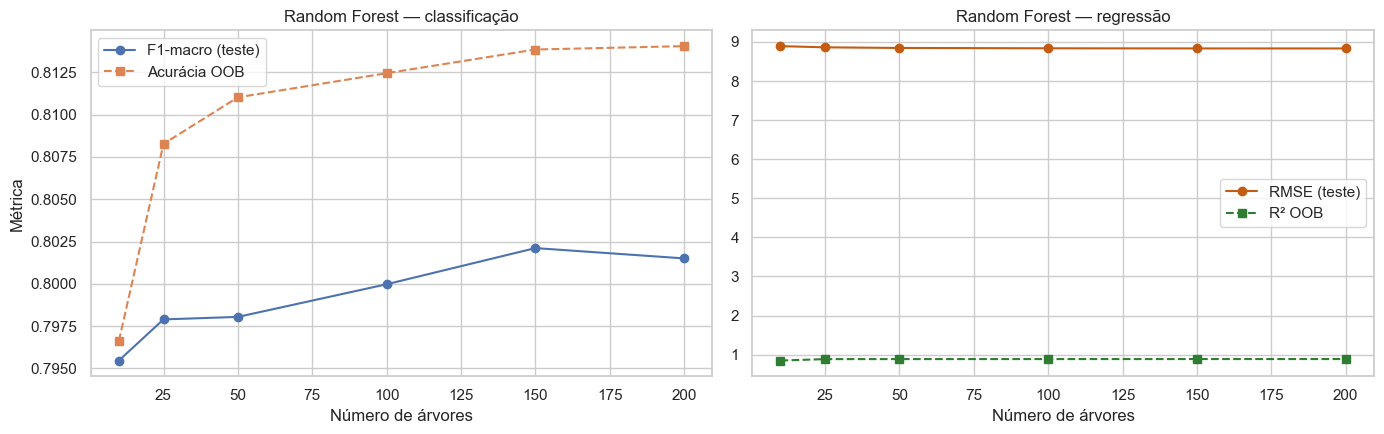

,n_arvores,oob_accuracy,f1_teste
0,10,0.7966,0.7955
1,25,0.8083,0.7979
2,50,0.8110,0.7980
3,100,0.8124,0.8000
4,150,0.8138,0.8021
5,200,0.8141,0.8015


,n_arvores,oob_r2,rmse_teste
0,10,0.8486,8.8933
1,25,0.8844,8.8626
2,50,0.8855,8.8467
3,100,0.8860,8.8377
4,150,0.8862,8.8345
5,200,0.8863,8.8336


In [7]:
contagens = [10, 25, 50, 100, 150, 200]
rf_curva_c = RandomForestClassifier(n_estimators=10, warm_start=True, oob_score=True,
                                     random_state=SEED, n_jobs=-1,
                                     **{k: v for k, v in busca_rf_c.best_params_.items() if k != 'n_estimators'})
curva_c = []
for n in contagens:
    rf_curva_c.set_params(n_estimators=n)
    rf_curva_c.fit(Xc_train, yc_train)
    curva_c.append({'n_arvores': n, 'oob_accuracy': rf_curva_c.oob_score_,
                    'f1_teste': metrics.classification_metrics(yc_test, rf_curva_c.predict(Xc_test))['F1 (macro)']})

rf_curva_r = RandomForestRegressor(n_estimators=10, warm_start=True, oob_score=True,
                                     random_state=SEED, n_jobs=-1,
                                     **{k: v for k, v in busca_rf_r.best_params_.items() if k != 'n_estimators'})
curva_r = []
for n in contagens:
    rf_curva_r.set_params(n_estimators=n)
    rf_curva_r.fit(Xr_train, yr_train)
    curva_r.append({'n_arvores': n, 'oob_r2': rf_curva_r.oob_score_,
                    'rmse_teste': metrics.regression_metrics(yr_test, rf_curva_r.predict(Xr_test))['RMSE']})

curva_c = pd.DataFrame(curva_c)
curva_r = pd.DataFrame(curva_r)
curva_c.to_csv(TABLES_DIR / '05_curva_rf_classificacao.csv', index=False)
curva_r.to_csv(TABLES_DIR / '05_curva_rf_regressao.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(curva_c['n_arvores'], curva_c['f1_teste'], 'o-', label='F1-macro (teste)')
axes[0].plot(curva_c['n_arvores'], curva_c['oob_accuracy'], 's--', label='Acurácia OOB')
axes[0].set_xlabel('Número de árvores'); axes[0].set_ylabel('Métrica')
axes[0].set_title('Random Forest — classificação'); axes[0].legend()

axes[1].plot(curva_r['n_arvores'], curva_r['rmse_teste'], 'o-', color='#c55a11', label='RMSE (teste)')
axes[1].plot(curva_r['n_arvores'], curva_r['oob_r2'], 's--', color='#2e7d32', label='R² OOB')
axes[1].set_xlabel('Número de árvores'); axes[1].set_title('Random Forest — regressão'); axes[1].legend()

plt.tight_layout()
plt.savefig(FIGURES_DIR / '05_curva_erro_random_forest.png', dpi=200, bbox_inches='tight')
plt.show()
display(curva_c.round(4))
display(curva_r.round(4))

## 6) Curva de aprendizado do Gradient Boosting (viés × variância)

`staged_predict_proba` permite acompanhar a perda logarítmica a cada árvore adicionada. A curva mostra o trade-off entre **viés** (poucas árvores, erro alto) e **variância** (árvores demais, risco de overfitting).

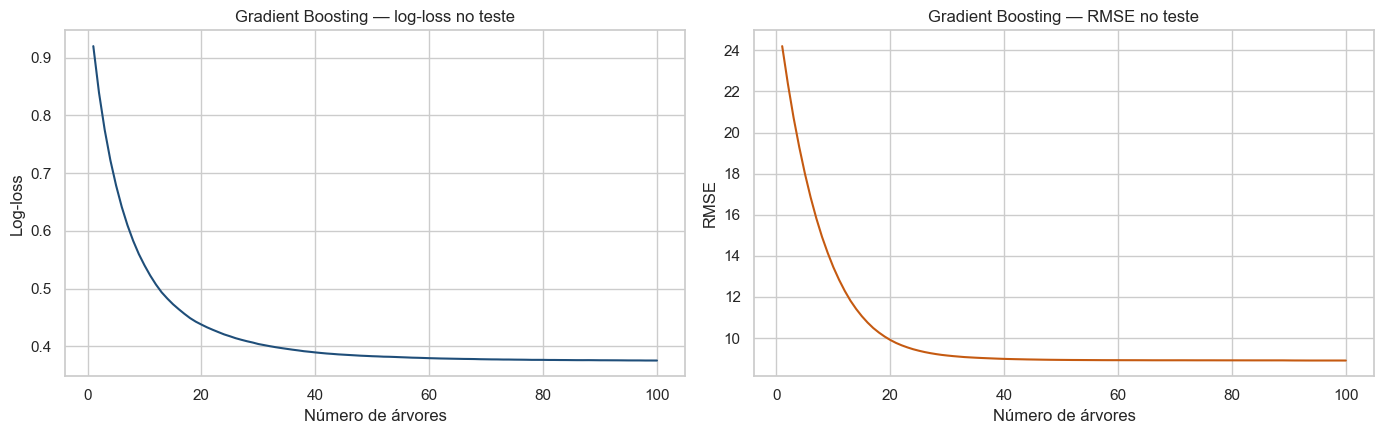

Log-loss mínima: 0.3756 em 100 árvores
RMSE mínimo: 8.9063 em 100 árvores


In [8]:
perdas = []
for i, proba in enumerate(gb_c.staged_predict_proba(Xc_test)):
    perdas.append({'n_arvores': i + 1,
                   'log_loss_teste': log_loss(yc_test, proba, labels=[0, 1, 2])})

rmse_stage = []
for i, pred in enumerate(gb_r.staged_predict(Xr_test)):
    rmse_stage.append({'n_arvores': i + 1,
                       'rmse_teste': metrics.regression_metrics(yr_test, pred)['RMSE']})

perdas = pd.DataFrame(perdas)
rmse_stage = pd.DataFrame(rmse_stage)
perdas.to_csv(TABLES_DIR / '05_curva_gb_classificacao.csv', index=False)
rmse_stage.to_csv(TABLES_DIR / '05_curva_gb_regressao.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(perdas['n_arvores'], perdas['log_loss_teste'], color='#1f4e79')
axes[0].set_xlabel('Número de árvores'); axes[0].set_ylabel('Log-loss')
axes[0].set_title('Gradient Boosting — log-loss no teste')
axes[1].plot(rmse_stage['n_arvores'], rmse_stage['rmse_teste'], color='#c55a11')
axes[1].set_xlabel('Número de árvores'); axes[1].set_ylabel('RMSE')
axes[1].set_title('Gradient Boosting — RMSE no teste')

plt.tight_layout()
plt.savefig(FIGURES_DIR / '05_curva_gradient_boosting.png', dpi=200, bbox_inches='tight')
plt.show()
print('Log-loss mínima: {:.4f} em {} árvores'.format(perdas['log_loss_teste'].min(), int(perdas.loc[perdas['log_loss_teste'].idxmin(), 'n_arvores'])))
print('RMSE mínimo: {:.4f} em {} árvores'.format(rmse_stage['rmse_teste'].min(), int(rmse_stage.loc[rmse_stage['rmse_teste'].idxmin(), 'n_arvores'])))

## 7) Importância das variáveis

Compara-se a importância por impureza do Random Forest e do Gradient Boosting. As mesmas variáveis que dominam as regras do especialista devem aparecer no topo.

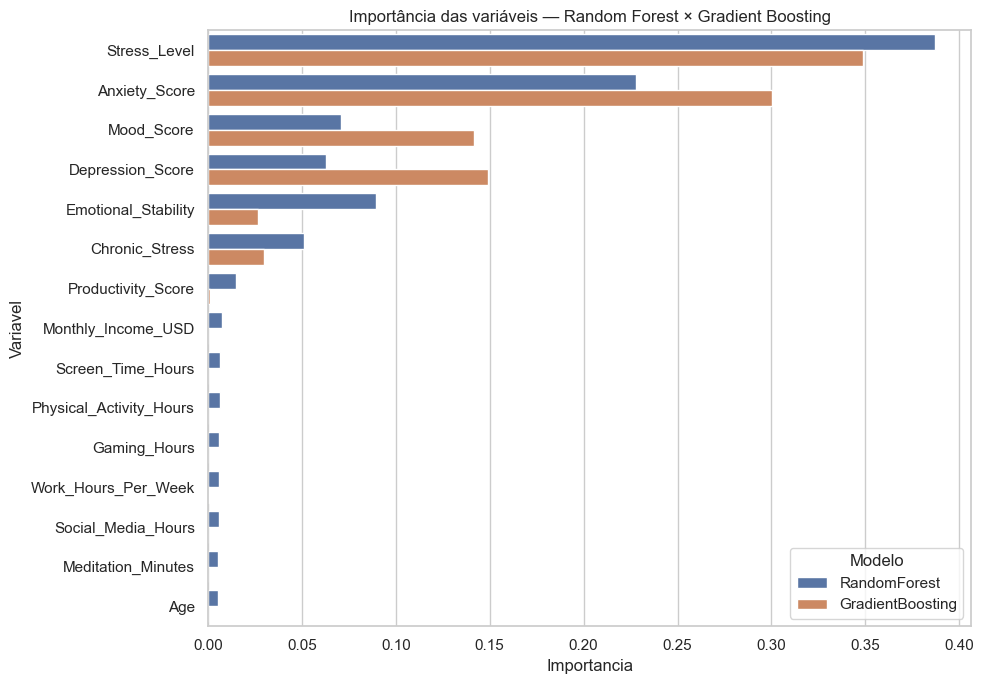

,Variavel,RandomForest,GradientBoosting,Media
8,Stress_Level,0.3869,0.3489,0.3679
9,Anxiety_Score,0.2279,0.3004,0.2641
11,Mood_Score,0.0706,0.1418,0.1062
10,Depression_Score,0.0628,0.1493,0.1061
12,Emotional_Stability,0.0896,0.0269,0.0583
23,Chronic_Stress,0.0510,0.0298,0.0404
28,Productivity_Score,0.0146,0.0013,0.0080
2,Monthly_Income_USD,0.0074,0.0001,0.0037
16,Screen_Time_Hours,0.0064,0.0001,0.0033
13,Physical_Activity_Hours,0.0062,0.0001,0.0031


In [9]:
imp_rf = pd.DataFrame({'Variavel': Xc_train.columns, 'RandomForest': rf_c.feature_importances_})
imp_gb = pd.DataFrame({'Variavel': Xc_train.columns, 'GradientBoosting': gb_c.feature_importances_})
importancias = imp_rf.merge(imp_gb, on='Variavel').sort_values('RandomForest', ascending=False)
importancias['Media'] = importancias[['RandomForest', 'GradientBoosting']].mean(axis=1)
importancias.to_csv(TABLES_DIR / '05_importancia_variaveis.csv', index=False)

top15 = importancias.sort_values('Media', ascending=False).head(15)
grafico = top15.melt(id_vars='Variavel', value_vars=['RandomForest', 'GradientBoosting'],
                     var_name='Modelo', value_name='Importancia')

plt.figure(figsize=(10, 7))
sns.barplot(data=grafico, y='Variavel', x='Importancia', hue='Modelo')
plt.title('Importância das variáveis — Random Forest × Gradient Boosting')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '05_importancia_ensemble.png', dpi=200, bbox_inches='tight')
plt.show()
top15.round(4)

## 8) Persistência dos modelos e tamanho em disco

Os modelos são salvos comprimidos (`joblib`, `compress=3`) para reuso nos notebooks 06 e 07.

In [10]:
artefatos = {
    'rf_classificacao': (rf_c, MODELOS_DIR / 'rf_classificacao.joblib'),
    'rf_regressao': (rf_r, MODELOS_DIR / 'rf_regressao.joblib'),
    'gb_classificacao': (gb_c, MODELOS_DIR / 'gb_classificacao.joblib'),
    'gb_regressao': (gb_r, MODELOS_DIR / 'gb_regressao.joblib'),
}
tamanhos = {}
for nome, (modelo, caminho) in artefatos.items():
    joblib.dump(modelo, caminho, compress=3)
    tamanhos[nome] = os.path.getsize(caminho) / 1024
    print(f'{nome}: {tamanhos[nome]:.2f} KB')

np.savez(REPORTS_DIR / 'predictions' / 'rf_classificacao.npz',
         y_true_test=yc_test.values, y_pred_test=pred_rf_c_te, y_proba_test=proba_rf_c_te,
         y_true_train=yc_train.values, y_pred_train=pred_rf_c_tr, y_proba_train=proba_rf_c_tr)
np.savez(REPORTS_DIR / 'predictions' / 'rf_regressao.npz',
         y_true_test=yr_test.values, y_pred_test=pred_rf_r_te,
         y_true_train=yr_train.values, y_pred_train=pred_rf_r_tr)
np.savez(REPORTS_DIR / 'predictions' / 'gb_classificacao.npz',
         y_true_test=yc_test.values, y_pred_test=pred_gb_c_te, y_proba_test=proba_gb_c_te,
         y_true_train=yc_train.values, y_pred_train=pred_gb_c_tr, y_proba_train=proba_gb_c_tr)
np.savez(REPORTS_DIR / 'predictions' / 'gb_regressao.npz',
         y_true_test=yr_test.values, y_pred_test=pred_gb_r_te,
         y_true_train=yr_train.values, y_pred_train=pred_gb_r_tr)

meta = {
    'rf_classificacao': {k: (v.item() if hasattr(v, 'item') else v) for k, v in busca_rf_c.best_params_.items()},
    'rf_regressao': {k: (v.item() if hasattr(v, 'item') else v) for k, v in busca_rf_r.best_params_.items()},
    'gb_classificacao': gb_params,
    'gb_regressao': gb_params,
    'tamanho_disco_kb': tamanhos,
    'tempo_treino_s': {
        'rf_classificacao': treino_rf_c['tempo_treinamento_s'],
        'rf_regressao': treino_rf_r['tempo_treinamento_s'],
        'gb_classificacao': treino_gb_c['tempo_treinamento_s'],
        'gb_regressao': treino_gb_r['tempo_treinamento_s'],
    },
    'pico_memoria_treino_kb': {
        'rf_classificacao': treino_rf_c['pico_memoria_treinamento_kb'],
        'rf_regressao': treino_rf_r['pico_memoria_treinamento_kb'],
        'gb_classificacao': treino_gb_c['pico_memoria_treinamento_kb'],
        'gb_regressao': treino_gb_r['pico_memoria_treinamento_kb'],
    },
}
(MODELOS_DIR / 'ensemble_meta.json').write_text(json.dumps(meta, indent=2, ensure_ascii=False), encoding='utf-8')

rf_classificacao: 2542.41 KB


rf_regressao: 2819.36 KB
gb_classificacao: 57.48 KB
gb_regressao: 25.74 KB


990

In [11]:
# Resultados consolidados (treino/teste) dos quatro modelos ensemble
linhas = []
for familia, modelo, problema, m_tr, m_te in [
    ('Ensemble (Random Forest)', 'RandomForest (n=100)', 'Classificacao', m_rf_c_tr, m_rf_c_te),
    ('Ensemble (Random Forest)', 'RandomForest (n=100)', 'Regressao', m_rf_r_tr, m_rf_r_te),
    ('Ensemble (Gradient Boosting)', 'GradientBoosting (n=100)', 'Classificacao', m_gb_c_tr, m_gb_c_te),
    ('Ensemble (Gradient Boosting)', 'GradientBoosting (n=100)', 'Regressao', m_gb_r_tr, m_gb_r_te),
]:
    for split, m in [('Treino', m_tr), ('Teste', m_te)]:
        linha = {'Familia': familia, 'Modelo': modelo, 'Problema': problema, 'Conjunto': split}
        linha.update(m)
        linhas.append(linha)

resultados = pd.DataFrame(linhas)
resultados.to_csv(TABLES_DIR / 'resultados_ensemble.csv', index=False)
resultados.round(4).to_string(index=False)

'                     Familia                   Modelo      Problema Conjunto  Accuracy  Precision (macro)  Recall (macro)  F1 (macro)  Precision (weighted)  Recall (weighted)  F1 (weighted)  ROC-AUC (OVR macro)  PR-AUC (macro)    MAE     MSE   RMSE  MAPE (%)     R²  MedAE  Cobertura MAPE (%)\n    Ensemble (Random Forest)     RandomForest (n=100) Classificacao   Treino    0.8630             0.8586          0.8470      0.8510                0.8690             0.8630         0.8647               0.9684          0.9272    NaN     NaN    NaN       NaN    NaN    NaN                 NaN\n    Ensemble (Random Forest)     RandomForest (n=100) Classificacao    Teste    0.8179             0.8048          0.7966      0.8000                0.8219             0.8179         0.8194               0.9463          0.8653    NaN     NaN    NaN       NaN    NaN    NaN                 NaN\n    Ensemble (Random Forest)     RandomForest (n=100)     Regressao   Treino       NaN                NaN            

## 9) Interpretação (viés × variância)

- A curva do Random Forest mostra que o erro cai rapidamente até ~50 árvores e depois estabiliza: mais árvores reduzem **variância**, não o **viés**.
- O Random Forest tende a apresentar *gap* treino-teste maior (cada árvore cresce até pureza); o Gradient Boosting, com árvores rasas e aprendizado sequencial, controla melhor o *gap*.
- As variáveis mais importantes coincidem com as usadas nas regras: ansiedade, depressão, humor, estabilidade emocional, produtividade e jornada.
- O Gradient Boosting tem custo de treino muito maior (sequencial) e inferência mais cara que a árvore, mas é o mais equilibrado em generalização.